In [1]:
from WF4Py import waveforms as WF;
from WF4Py import WFutils as utils;

import numpy as np
from astropy.cosmology import Planck18

import pycbc.conversions as cvs;
import pycbc.waveform as wf;
import pycbc.types as tps;

import time
import sys
import os

import matplotlib.pyplot as pp
from matplotlib import gridspec
from matplotlib import rc
rc('text', usetex=False)


ourcodenameString = 'WF4Py'

/workspace/minconda3/envs/preload/lib/python3.9/site-packages/pycbc/types/array.py:36: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal as _lal
/workspace/minconda3/envs/preload/lib/python3.9/site-packages/pykerr/qnm.py:2: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  im

In [2]:
zs = np.array([.2, .5, .7])

# events0 = {'Mc':np.array([30, 45, 60])*(1.+zs),
#           'dL':(Planck18.luminosity_distance(zs).value/1000.),
#           'iota':np.array([.0, .4, np.pi]),
#           'eta':np.array([0.24, .23, .2499]),
#           'chi1z':np.array([0.8, .5, 0.]),
#           'chi2z':np.array([-0.8, 0., -.2]),

#           'f_lower': np.array([15]),}

events = {'Mc':np.array([cvs.mchirp_from_mass1_mass2(33,12)]),
          'dL':np.array([137]),
          'iota':np.array([0*np.pi]),
          'eta':np.array([cvs.eta_from_mass1_mass2(33,12)]),
          'chi1z':np.array([0.8]),
          'chi2z':np.array([0.57]),
          'f_lower': np.array([100]),
          'f_final': np.array([2048])}

# Note that this model has various versions for both the phase and the amplitude
tmpWF = WF.IMRPhenomXAS(InsPhaseVersion=104, IntPhaseVersion=105, IntAmpVersion=104)

fcut = tmpWF.fcut(**events)
# fcut = tmpWF.fcut(**events)
fminarr = np.full(fcut.shape, 5)
fgrids = np.geomspace(fminarr, fcut, num=int(1000))

myampl = tmpWF.Ampl(fgrids, **events)
myphase = tmpWF.Phi(fgrids, **events)
originphase = tmpWF.Phi0(fgrids, **events)

In [3]:
events = dict(
    mass1 = 33,
    mass2 = 12,
    spin1z = 0.8,
    spin2z = 0.57,
    distance = 0.137,
    # inclination = -np.pi/3,
    inclination = 0,
    coa_phase = 12.0,

    f_lower = 100,
    delta_f = 1/16,
    f_final = 2048,
)

tmpWF = WF.IMRPhenomXAS()
fcut = tmpWF.fcut(**events|{"Mc": np.array([cvs.mchirp_from_mass1_mass2(events['mass1'],events['mass2'])]), "eta": np.array([cvs.eta_from_mass1_mass2(events['mass1'],events['mass2'])])})
fminarr = np.full(fcut.shape, events["f_lower"])
delta_f = events["delta_f"]
fgrids = np.arange(fminarr, fcut, delta_f)
fgrids = fgrids.reshape(-1, 1)

hp1, hc1 = wf.get_fd_waveform(approximant='dchi_modified_IMRPhenomXAS',
                                                    mass1=events['mass1'],
                                                    mass2=events['mass2'],
                                                    spin1z=events['spin1z'],
                                                    spin2z=events['spin2z'],
                                                    delta_f=events["delta_f"],
                                                    distance=events['distance'],
                                                    # mode_array = [[2,2]],
                                                    inclination=events['inclination'],
                                                    f_final=events['f_final'],
                                                    f_lower=events["f_lower"],
                                                    # f_ref = 100,
                                                    if_dchi0=False,
                                                    if_dchi1=False,
                                                    if_dchi2=False,
                                                    if_dchi3=False,
                                                    if_dchi4=False,
                                                    if_dchi5l=False,
                                                    if_dchi5=False,
                                                    if_dchi6=False,
                                                    if_dchi6l=False,
                                                    if_dchi7=False,
                                                    if_dchi8=False,
                                                    if_dchi8l=False,
                                                    )

/tmp/ipykernel_4046201/694864834.py:20: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  fgrids = np.arange(fminarr, fcut, delta_f)
/workspace/minconda3/envs/preload/lib/python3.9/site-packages/WF4Py/waveform_models/IMRPhenomXAS.py:1628: RuntimeWarning: divide by zero encountered in power
  return np.nan_to_num(Overallamp * amplitudeIMR * (fgrid**(-7./6.)), 0)
/workspace/minconda3/envs/preload/lib/python3.9/site-packages/WF4Py/waveform_models/IMRPhenomXAS.py:1628: RuntimeWarning: invalid value encountered in multiply
  return np.nan_to_num(Overallamp * amplitudeIMR * (fgrid**(-7./6.)), 0)
/workspace/minconda3/envs/preload/lib/python3.9/site-packages/WF4Py/waveform_models/IMRPhenomXAS.py:567: RuntimeWarning: divide by zero encountered in power
  inspiral_phases = phiNorm*(inspiral_freqs**(-5./3.))*(
/workspace/minco

In [4]:

hp2, hc2 = wf.get_fd_waveform(approximant='IMRPhenomXAS',
                                                    mass1=events['mass1'],
                                                    mass2=events['mass2'],
                                                    spin1z=events['spin1z'],
                                                    spin2z=events['spin2z'],
                                                    delta_f=events["delta_f"],
                                                    distance=events['distance'],
                                                    # mode_array = [[2,2]],
                                                    inclination=events['inclination'],
                                                    f_final=events['f_final'],
                                                    f_lower=events["f_lower"]
                                                    )

In [5]:
1 - np.sum(np.conj(hp1.data)*hp2.data[:32768])/np.sum(np.conj(hp2.data)*hp2.data)

(4.223703391303957e-05-0.0047831273794507155j)

In [6]:
1 - np.sum(np.conj(hp1_dchi3.data)*hp2.data[:32768])/np.sum(np.conj(hp2.data)*hp2.data)

NameError: name 'hp1_dchi3' is not defined

In [7]:
hp1_dchi0, hc1_dchi0 = wf.get_fd_waveform(approximant='dchi_modified_IMRPhenomXAS',
                                                    mass1=events['mass1'],
                                                    mass2=events['mass2'],
                                                    spin1z=events['spin1z'],
                                                    spin2z=events['spin2z'],
                                                    delta_f=events["delta_f"],
                                                    distance=events['distance'],
                                                    # mode_array = [[2,2]],
                                                    inclination=events['inclination'],
                                                    f_final=events['f_final'],
                                                    f_lower=events["f_lower"],
                                                    dchi0=21908.934774088466,
                                                    if_dchi0=True,
                                                    if_dchi1=False,
                                                    if_dchi2=False,
                                                    if_dchi3=False,
                                                    if_dchi4=False,
                                                    if_dchi5l=False,
                                                    if_dchi5=False,
                                                    if_dchi6=False,
                                                    if_dchi6l=False,
                                                    if_dchi7=False,
                                                    if_dchi8=False,
                                                    if_dchi8l=False,
                                                    )

hp1_dchi1, hc1_dchi1 = wf.get_fd_waveform(approximant='dchi_modified_IMRPhenomXAS',
                                                    mass1=events['mass1'],
                                                    mass2=events['mass2'],
                                                    spin1z=events['spin1z'],
                                                    spin2z=events['spin2z'],
                                                    delta_f=events["delta_f"],
                                                    distance=events['distance'],
                                                    # mode_array = [[2,2]],
                                                    inclination=events['inclination'],
                                                    f_final=events['f_final'],
                                                    f_lower=events["f_lower"],
                                                    dchi1=0.,
                                                    if_dchi0=False,
                                                    if_dchi1=True,
                                                    if_dchi2=False,
                                                    if_dchi3=False,
                                                    if_dchi4=False,
                                                    if_dchi5l=False,
                                                    if_dchi5=False,
                                                    if_dchi6=False,
                                                    if_dchi6l=False,
                                                    if_dchi7=False,
                                                    if_dchi8=False,
                                                    if_dchi8l=False,
                                                    )

hp1_dchi2, hc1_dchi2 = wf.get_fd_waveform(approximant='dchi_modified_IMRPhenomXAS',
                                                    mass1=events['mass1'],
                                                    mass2=events['mass2'],
                                                    spin1z=events['spin1z'],
                                                    spin2z=events['spin2z'],
                                                    delta_f=events["delta_f"],
                                                    distance=events['distance'],
                                                    # mode_array = [[2,2]],
                                                    inclination=events['inclination'],
                                                    f_final=events['f_final'],
                                                    f_lower=events["f_lower"],
                                                    dchi2=1051.4901921172077,
                                                    if_dchi0=False,
                                                    if_dchi1=False,
                                                    if_dchi2=True,
                                                    if_dchi3=False,
                                                    if_dchi4=False,
                                                    if_dchi5l=False,
                                                    if_dchi5=False,
                                                    if_dchi6=False,
                                                    if_dchi6l=False,
                                                    if_dchi7=False,
                                                    if_dchi8=False,
                                                    if_dchi8l=False,
                                                    )

hp1_dchi3, hc1_dchi3 = wf.get_fd_waveform(approximant='dchi_modified_IMRPhenomXAS',
                                                    mass1=events['mass1'],
                                                    mass2=events['mass2'],
                                                    spin1z=events['spin1z'],
                                                    spin2z=events['spin2z'],
                                                    delta_f=events["delta_f"],
                                                    distance=events['distance'],
                                                    # mode_array = [[2,2]],
                                                    inclination=events['inclination'],
                                                    f_final=events['f_final'],
                                                    f_lower=events["f_lower"],
                                                    dchi3=-394.14586894,
                                                    if_dchi0=False,
                                                    if_dchi1=False,
                                                    if_dchi2=False,
                                                    if_dchi3=True,
                                                    if_dchi4=False,
                                                    if_dchi5l=False,
                                                    if_dchi5=False,
                                                    if_dchi6=False,
                                                    if_dchi6l=False,
                                                    if_dchi7=False,
                                                    if_dchi8=False,
                                                    if_dchi8l=False,
                                                    )

hp1_dchi4, hc1_dchi4 = wf.get_fd_waveform(approximant='dchi_modified_IMRPhenomXAS',
                                                    mass1=events['mass1'],
                                                    mass2=events['mass2'],
                                                    spin1z=events['spin1z'],
                                                    spin2z=events['spin2z'],
                                                    delta_f=events["delta_f"],
                                                    distance=events['distance'],
                                                    # mode_array = [[2,2]],
                                                    inclination=events['inclination'],
                                                    f_final=events['f_final'],
                                                    f_lower=events["f_lower"],
                                                    dchi4=20.11334056036653,
                                                    if_dchi0=False,
                                                    if_dchi1=False,
                                                    if_dchi2=False,
                                                    if_dchi3=False,
                                                    if_dchi4=True,
                                                    if_dchi5l=False,
                                                    if_dchi5=False,
                                                    if_dchi6=False,
                                                    if_dchi6l=False,
                                                    if_dchi7=False,
                                                    if_dchi8=False,
                                                    if_dchi8l=False,
                                                    )

hp1_dchi6, hc1_dchi6 = wf.get_fd_waveform(approximant='dchi_modified_IMRPhenomXAS',
                                                    mass1=events['mass1'],
                                                    mass2=events['mass2'],
                                                    spin1z=events['spin1z'],
                                                    spin2z=events['spin2z'],
                                                    delta_f=events["delta_f"],
                                                    distance=events['distance'],
                                                    # mode_array = [[2,2]],
                                                    inclination=events['inclination'],
                                                    f_final=events['f_final'],
                                                    f_lower=events["f_lower"],
                                                    dchi6=14.641858124785827,
                                                    if_dchi0=False,
                                                    if_dchi1=False,
                                                    if_dchi2=False,
                                                    if_dchi3=False,
                                                    if_dchi4=False,
                                                    if_dchi5l=False,
                                                    if_dchi5=False,
                                                    if_dchi6=True,
                                                    if_dchi6l=False,
                                                    if_dchi7=False,
                                                    if_dchi8=False,
                                                    if_dchi8l=False,
                                                    )

hp1_dchi6l, hc1_dchi6l = wf.get_fd_waveform(approximant='dchi_modified_IMRPhenomXAS',
                                                    mass1=events['mass1'],
                                                    mass2=events['mass2'],
                                                    spin1z=events['spin1z'],
                                                    spin2z=events['spin2z'],
                                                    delta_f=events["delta_f"],
                                                    distance=events['distance'],
                                                    # mode_array = [[2,2]],
                                                    inclination=events['inclination'],
                                                    f_final=events['f_final'],
                                                    f_lower=events["f_lower"],
                                                    dchi6l=-1.1546977026861354,
                                                    if_dchi0=False,
                                                    if_dchi1=False,
                                                    if_dchi2=False,
                                                    if_dchi3=False,
                                                    if_dchi4=False,
                                                    if_dchi5l=False,
                                                    if_dchi5=False,
                                                    if_dchi6=False,
                                                    if_dchi6l=True,
                                                    if_dchi7=False,
                                                    if_dchi8=False,
                                                    if_dchi8l=False,
                                                    )

hp1_dchi5l, hc1_dchi5l = wf.get_fd_waveform(approximant='dchi_modified_IMRPhenomXAS',
                                                    mass1=events['mass1'],
                                                    mass2=events['mass2'],
                                                    spin1z=events['spin1z'],
                                                    spin2z=events['spin2z'],
                                                    delta_f=events["delta_f"],
                                                    distance=events['distance'],
                                                    # mode_array = [[2,2]],
                                                    inclination=events['inclination'],
                                                    f_final=events['f_final'],
                                                    f_lower=events["f_lower"],
                                                    dchi5l=-4.988853401753867,
                                                    if_dchi0=False,
                                                    if_dchi1=False,
                                                    if_dchi2=False,
                                                    if_dchi3=False,
                                                    if_dchi4=False,
                                                    if_dchi5l=True,
                                                    if_dchi5=False,
                                                    if_dchi6=False,
                                                    if_dchi6l=False,
                                                    if_dchi7=False,
                                                    if_dchi8=False,
                                                    if_dchi8l=False,
                                                    )

hp1_dchi7, hc1_dchi7 = wf.get_fd_waveform(approximant='dchi_modified_IMRPhenomXAS',
                                                    mass1=events['mass1'],
                                                    mass2=events['mass2'],
                                                    spin1z=events['spin1z'],
                                                    spin2z=events['spin2z'],
                                                    delta_f=events["delta_f"],
                                                    distance=events['distance'],
                                                    # mode_array = [[2,2]],
                                                    inclination=events['inclination'],
                                                    f_final=events['f_final'],
                                                    f_lower=events["f_lower"],
                                                    dchi7=-3.602648446577167,
                                                    if_dchi0=False,
                                                    if_dchi1=False,
                                                    if_dchi2=False,
                                                    if_dchi3=False,
                                                    if_dchi4=False,
                                                    if_dchi5l=False,
                                                    if_dchi5=False,
                                                    if_dchi6=False,
                                                    if_dchi6l=False,
                                                    if_dchi7=True,
                                                    if_dchi8=False,
                                                    if_dchi8l=False,
                                                    )

/workspace/minconda3/envs/preload/lib/python3.9/site-packages/WF4Py/waveform_models/IMRPhenomXAS.py:604: RuntimeWarning: divide by zero encountered in power
  inspiral_phases -= phiNorm * ( phi0*(inspiral_freqs**(-5./3.)) ) * inspiral_freqs**(0./3.)
/workspace/minconda3/envs/preload/lib/python3.9/site-packages/WF4Py/waveform_models/IMRPhenomXAS.py:605: RuntimeWarning: divide by zero encountered in power
  inspiral_phases += - eta * ( kwargs["dchi0"]/(M*utils.GMsun_over_c3)**((-5.+0.)/3.)*inspiral_freqs**(0./3.) ) *inspiral_freqs**(-5./3.)
/workspace/minconda3/envs/preload/lib/python3.9/site-packages/WF4Py/waveform_models/IMRPhenomXAS.py:616: RuntimeWarning: divide by zero encountered in power
  inspiral_phases -= phiNorm * ( phi1*(inspiral_freqs**(-5./3.)) ) * inspiral_freqs**(1./3.)
/workspace/minconda3/envs/preload/lib/python3.9/site-packages/WF4Py/waveform_models/IMRPhenomXAS.py:616: RuntimeWarning: invalid value encountered in multiply
  inspiral_phases -= phiNorm * ( phi1*(inspira

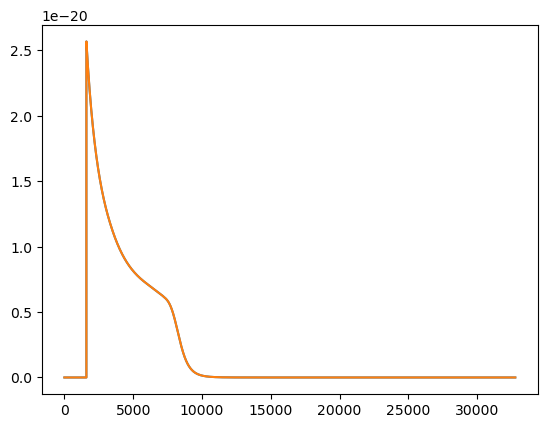

In [7]:
pp.plot(np.abs(hp1.data))
pp.plot(np.abs(hp2.data))

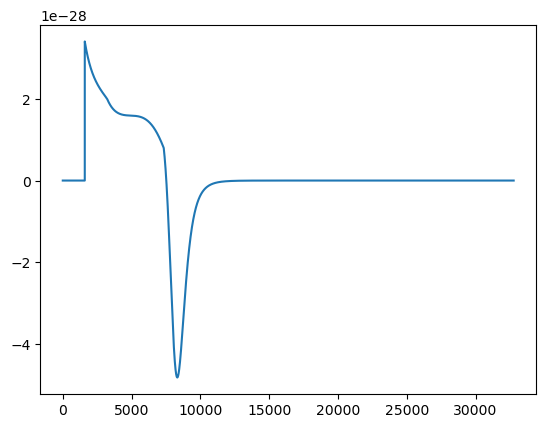

In [ ]:
pp.plot(np.abs(hp1.data)-np.abs(hp2.data)[:32768])
# pp.plot()

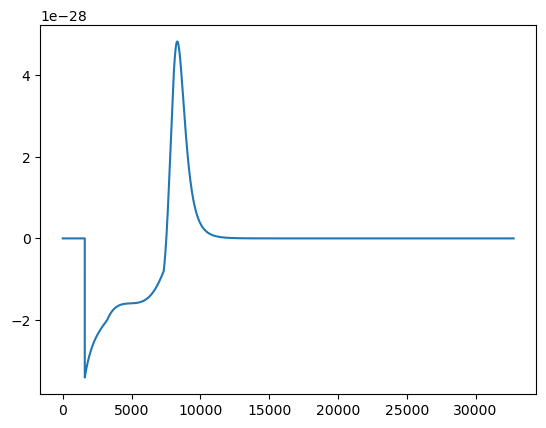

In [ ]:
pp.plot(np.abs(hp2.data)[:32768]-np.abs(hp1_dchi3.data))

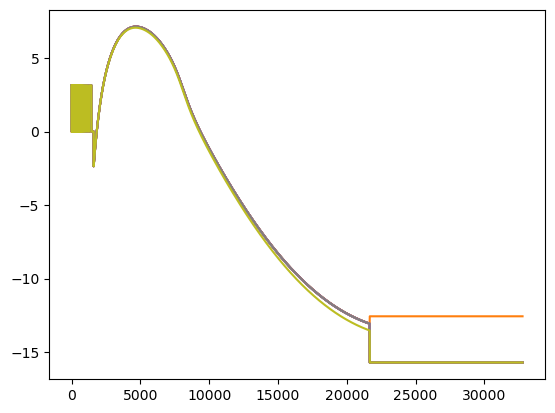

In [ ]:
pp.plot(np.unwrap(np.angle(hp1.data)))
pp.plot(np.unwrap(np.angle(hp2.data)))
pp.plot(np.unwrap(np.angle(hp1_dchi0.data)))
# pp.plot(np.unwrap(np.angle(hp1_dchi1.data)))
pp.plot(np.unwrap(np.angle(hp1_dchi2.data)))
pp.plot(np.unwrap(np.angle(hp1_dchi3.data)))
pp.plot(np.unwrap(np.angle(hp1_dchi4.data)))
# pp.plot(np.unwrap(np.angle(hp1_dchi6.data)))
pp.plot(np.unwrap(np.angle(hp1_dchi6l.data)))
pp.plot(np.unwrap(np.angle(hp1_dchi5l.data)))
# pp.plot(np.unwrap(np.angle(hp1_dchi7.data)))
# pp.xlim([15000,20000])
# pp.ylim([240,250])

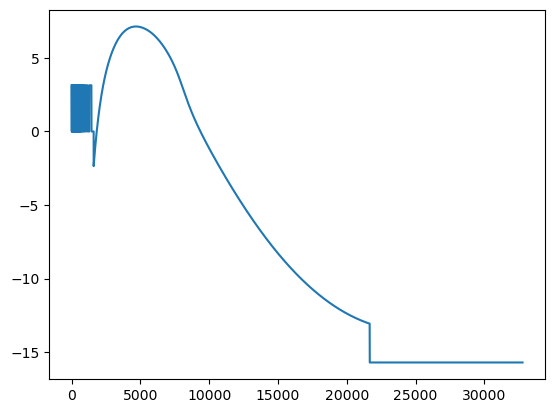

In [10]:
pp.plot(np.unwrap(np.angle(hp1_dchi4.data)))

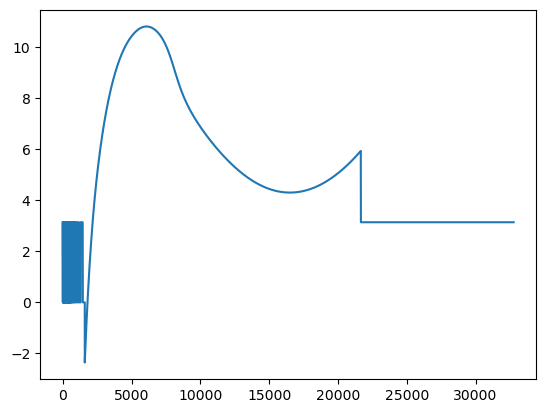

In [13]:
pp.plot(np.unwrap(np.angle(hp1_dchi6.data)))

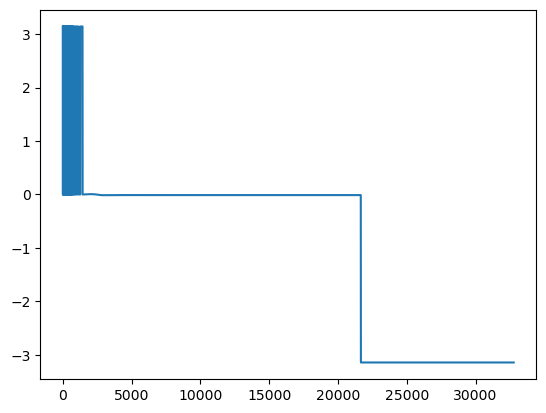

In [29]:
pp.plot(np.unwrap(np.angle(hp1.data))-np.unwrap(np.angle(hp2.data[:len(hp1.data)])))
# pp.xlim([0,250])
# pp.xlim([300, 10000])

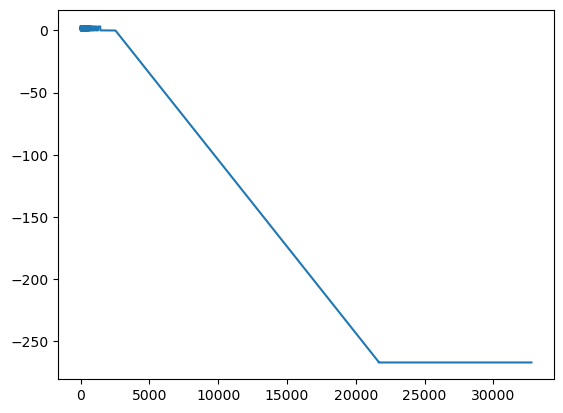

In [17]:
pp.plot(np.unwrap(np.angle(hp1_dchi1.data))-np.unwrap(np.angle(hp2.data[:len(hp1.data)])))

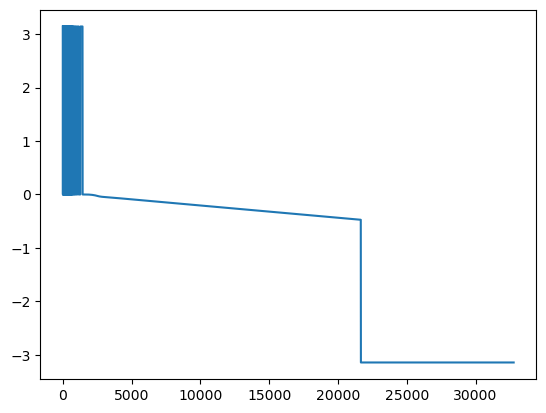

In [13]:
pp.plot(np.unwrap(np.angle(hp1_dchi7.data))-np.unwrap(np.angle(hp2.data[:len(hp1.data)])))

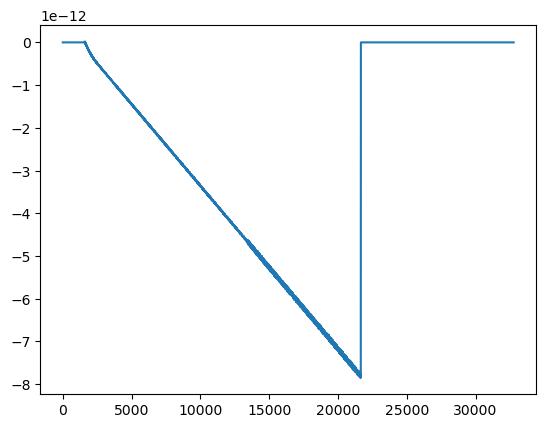

In [32]:
pp.plot(np.unwrap(np.angle(hp1_dchi3.data))-np.unwrap(np.angle(hp1.data)))

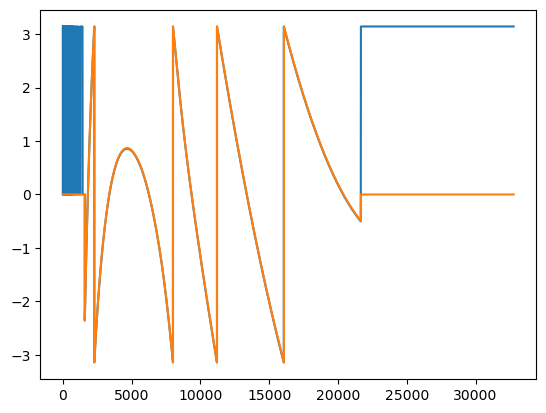

In [33]:
pp.plot(np.angle(hp1.data))
pp.plot(np.angle(hp2.data[:len(hp1.data)]))
# pp.xlim([0,1000])

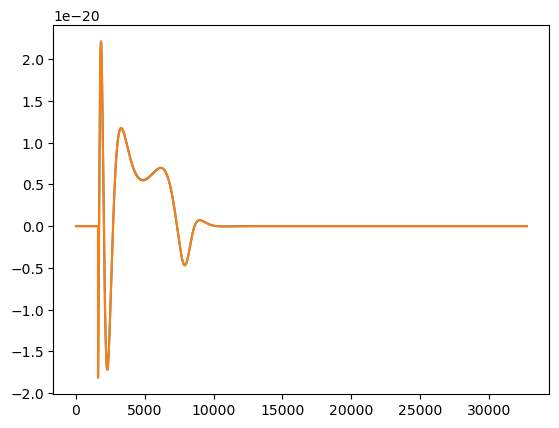

In [34]:
pp.plot(hp1)
pp.plot(hp2)

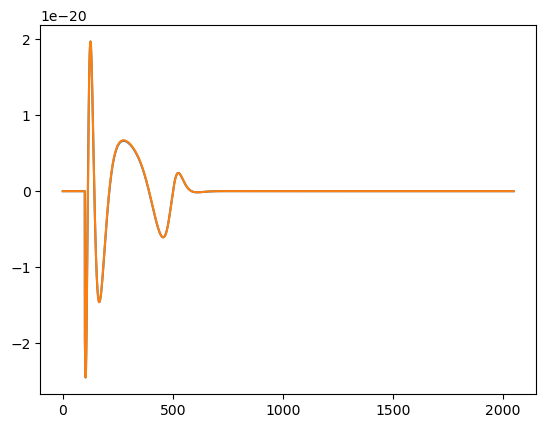

In [35]:
pp.plot(hp1.sample_frequencies, np.imag(hp1.data))
pp.plot(hp2.sample_frequencies, np.imag(hp2.data))

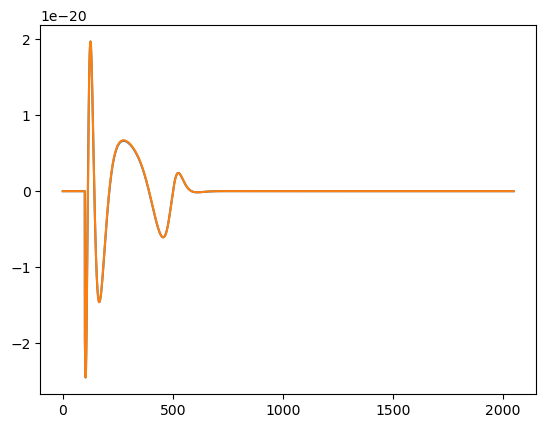

In [36]:
pp.plot(hp1.sample_frequencies, np.real(hc1.data))
pp.plot(hp2.sample_frequencies, np.real(hc2.data))

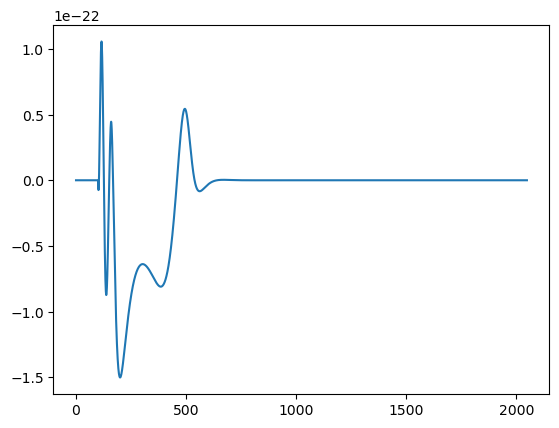

In [37]:
pp.plot(hp1.sample_frequencies, np.real(hc1.data)-np.real(hc2.data[:len(hc1.data)]))


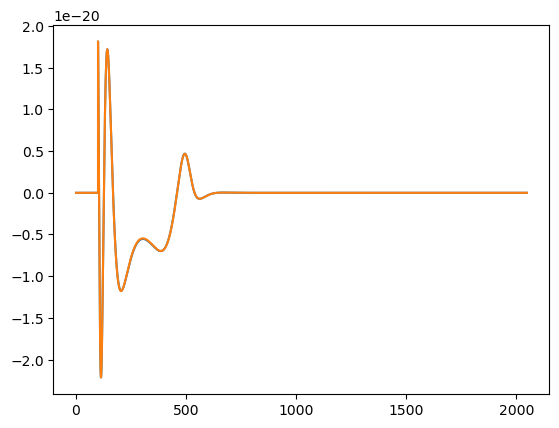

In [38]:
pp.plot(hp1.sample_frequencies, np.imag(hc1.data))
pp.plot(hp2.sample_frequencies, np.imag(hc2.data))

(0.0, 300.0)

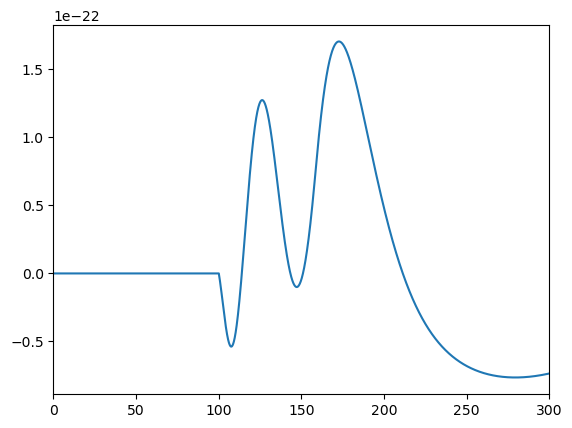

In [40]:
pp.plot(hp1.sample_frequencies, np.imag(hc1.data)-np.imag(hc2.data[:len(hc1.data)]))
pp.xlim([0, 300])
# pp.plot(hp2.sample_frequencies, )